# 实验3 MNIST 全连接与 CNN 对照

完成四组对照：原图 FNN、原图 CNN、固定像素置换 FNN、相同置换 CNN。保留指导中的两种网络与 SGD 参数；两个网络参数量接近但并非完全相等。默认各训练 1 个 epoch，与指导中的一次 train 调用对应。

[原实验指导](https://oucaigroup.feishu.cn/wiki/ZZHiwlpZJiLuNCkpL5ScHeCTnqg)

在 Colab：上传本 ipynb → 选择 GPU → 从上到下运行。三个 Notebook 各自独立，无需上传其他源码。下方没有预填训练输出，指标与图片由真实运行生成。


## 1 环境检查

Colab 通常已带 PyTorch、Torchvision、NumPy 和 Matplotlib。此处打印实际版本和设备，不强行覆盖 Colab 预装的 GPU 环境。若缺包，先看文件夹中的运行说明；GPU 应在开始运行前选好。


In [4]:
import csv
import json
import math
import platform
import random
import shutil
import sys
import time
from datetime import datetime
from pathlib import Path

try:
    import numpy as np
    import matplotlib.pyplot as plt
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torch.utils.data import DataLoader, Subset
    from torchvision import datasets, transforms
except ImportError as exc:
    raise RuntimeError(
        "缺少依赖。在 Colab 中选择 Python 3 运行环境；本地先安装 requirements.txt。"
    ) from exc

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("当前使用 CPU；完整训练建议在 Colab 选择 GPU。")


Python: 3.13.15
PyTorch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
Device: cuda:0
GPU: Tesla T4


## 2 实验参数

默认参数对应指导。首次只想检查流程，可把 smoke_test 改为 True；正式实验再改回 False，并从本单元重新运行到最后。download_results=True 可在 Colab 最后自动下载结果。


In [5]:
# 所有可调参数集中在这里；正式实验保持 smoke_test=False。
EXPERIMENT_ID = 'lab03_mnist_cnn'
SOURCE_URL = 'https://oucaigroup.feishu.cn/wiki/ZZHiwlpZJiLuNCkpL5ScHeCTnqg'
CFG = {'seed': 42,
 'data_root': './data',
 'output_root': './outputs',
 'smoke_test': False,
 'save_models': True,
 'download_results': False,
 'dataset': 'MNIST',
 'epochs': 1,
 'train_batch_size': 64,
 'test_batch_size': 1000,
 'optimizer': 'SGD',
 'learning_rate': 0.01,
 'momentum': 0.5,
 'augmentation': False}
CFG['num_workers'] = 0
MEAN = (0.1307,)
STD = (0.3081,)
CLASSES = ('0', '1', '2', '3', '4', '5', '6', '7', '8', '9')
set_config_note = 'smoke_test=True 时仅取真实数据 1024/256 张、训练 1 轮。'
assert CFG['epochs'] >= 1 and CFG['train_batch_size'] >= 2


## 3 训练 测试与可视化工具

训练与测试分离，测试使用 eval 和 inference_mode；每个 epoch 保存日志。测试集用于观察固定轮次的结果，不按测试准确率挑选最佳模型或调参。


In [6]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    # DataLoader 会设置每个 worker 的 torch 种子；同步 Python 和 numpy。
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed)
    np.random.seed(seed)


def create_run_directory():
    run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    directory = Path(CFG["output_root"]) / EXPERIMENT_ID / run_id
    directory.mkdir(parents=True, exist_ok=False)
    config = {
        "experiment": EXPERIMENT_ID, "source": SOURCE_URL, "config": CFG,
        "device": str(DEVICE), "torch": str(torch.__version__),
        "torchvision": str(torchvision.__version__), "python": sys.version,
        "mean": MEAN, "std": STD, "classes": CLASSES,
        "scope": "real-data subset smoke test" if CFG["smoke_test"] else "full dataset",
    }
    (directory / "config.json").write_text(
        json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("Outputs:", directory.resolve())
    if CFG["smoke_test"]:
        print("SMOKE TEST：真实数据小子集，仅检查流程，不能当作完整实验成绩。")
    return directory


def load_datasets():
    train_steps = []
    if CFG["augmentation"]:
        train_steps += [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
    normalize = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    train_transform = transforms.Compose(train_steps + normalize)
    test_transform = transforms.Compose(normalize)
    dataset_class = datasets.MNIST if CFG["dataset"] == "MNIST" else datasets.CIFAR10
    try:
        train_data = dataset_class(CFG["data_root"], train=True, download=True, transform=train_transform)
        test_data = dataset_class(CFG["data_root"], train=False, download=True, transform=test_transform)
    except Exception as exc:
        raise RuntimeError(
            "真实数据集读取或下载失败。请检查网络、磁盘与 data_root，修复后重跑本单元；"
            "本代码不会自动切换到随机数据。"
        ) from exc
    if CFG["smoke_test"]:
        generator = torch.Generator().manual_seed(CFG["seed"])
        train_indices = torch.randperm(len(train_data), generator=generator)[:1024].tolist()
        test_indices = torch.randperm(len(test_data), generator=generator)[:256].tolist()
        train_data = Subset(train_data, train_indices)
        test_data = Subset(test_data, test_indices)
    print("Training samples:", len(train_data), "Test samples:", len(test_data))
    print("Train transform:", train_transform)
    print("Test transform:", test_transform)
    return train_data, test_data


def make_loader(dataset, training):
    generator = torch.Generator().manual_seed(CFG["seed"])
    return DataLoader(
        dataset,
        batch_size=CFG["train_batch_size"] if training else CFG["test_batch_size"],
        shuffle=training,
        num_workers=CFG["num_workers"],
        pin_memory=DEVICE.type == "cuda",
        worker_init_fn=seed_worker,
        generator=generator,
    )


def display_image(ax, image):
    image = image.detach().cpu()
    mean = torch.tensor(MEAN).view(-1, 1, 1)
    std = torch.tensor(STD).view(-1, 1, 1)
    image = (image * std + mean).clamp(0, 1)
    if image.shape[0] == 1:
        ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
    else:
        ax.imshow(image.permute(1, 2, 0).numpy())
    ax.axis("off")


def show_samples(dataset, directory):
    count = min(16, len(dataset))
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for index, ax in enumerate(axes.flat):
        if index < count:
            image, label = dataset[index]
            display_image(ax, image)
            ax.set_title(CLASSES[int(label)])
        else:
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(directory / "data_samples.png", dpi=160)
    plt.show()
    plt.close(fig)


def apply_permutation(images, permutation):
    if permutation is None:
        return images
    if tuple(images.shape[1:]) != (1, 28, 28) or permutation.numel() != 784:
        raise ValueError("像素置换只用于 1×28×28 的 MNIST 图像。")
    return images.flatten(1)[:, permutation].reshape_as(images)


def forward_shape_table(model, input_shape):
    hooks = []
    records = []
    def record(name):
        def hook(module, inputs, output):
            records.append((name, type(module).__name__, tuple(output.shape)))
        return hook
    for name, module in model.named_modules():
        if name and not list(module.children()):
            hooks.append(module.register_forward_hook(record(name)))
    previous_mode = model.training
    try:
        model.eval()
        with torch.inference_mode():
            output = model(torch.zeros(input_shape, device=DEVICE))
        assert tuple(output.shape) == (input_shape[0], 10), tuple(output.shape)
    finally:
        for hook in hooks:
            hook.remove()
        model.train(previous_mode)
    print("Layer | Type | Output shape")
    for row in records:
        print(" | ".join(map(str, row)))
    print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
    return records


def train_one_epoch(model, loader, criterion, optimizer, permutation=None):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for batch_index, (images, labels) in enumerate(loader):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        images = apply_permutation(images, permutation)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("训练损失不是有限值，请检查输入与学习率。")
        loss.backward()
        optimizer.step()
        size = labels.size(0)
        loss_sum += loss.item() * size
        correct += (logits.argmax(1) == labels).sum().item()
        count += size
        if batch_index % 100 == 0:
            print(f"  Batch {batch_index + 1}/{len(loader)} | loss={loss.item():.4f}")
    return loss_sum / count, 100.0 * correct / count


@torch.inference_mode()
def evaluate(model, loader, criterion, permutation=None):
    # VGG 含 BatchNorm，测试必须切换 eval，防止更新统计量。
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(apply_permutation(images, permutation))
        loss_sum += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        count += labels.size(0)
    return loss_sum / count, 100.0 * correct / count, count


def fit_model(model, name, train_data, test_data, directory, criterion, permutation=None):
    # 每个模型重置随机种子与 loader，控制初始化、批次顺序和数据增强。
    set_seed(CFG["seed"])
    train_loader = make_loader(train_data, True)
    test_loader = make_loader(test_data, False)
    optimizer_class = torch.optim.SGD if CFG["optimizer"] == "SGD" else torch.optim.Adam
    optimizer_options = {"lr": CFG["learning_rate"]}
    if CFG["optimizer"] == "SGD":
        optimizer_options["momentum"] = CFG["momentum"]
    optimizer = optimizer_class(model.parameters(), **optimizer_options)
    if permutation is not None:
        permutation = permutation.to(DEVICE)
    history = []
    model_directory = directory / name
    model_directory.mkdir(parents=True, exist_ok=True)
    epochs = 1 if CFG["smoke_test"] else CFG["epochs"]
    print(f"\n{name}: {sum(p.numel() for p in model.parameters()):,} parameters, {epochs} epoch(s)")
    for epoch in range(1, epochs + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, permutation)
        test_loss, test_accuracy, tested = evaluate(model, test_loader, criterion, permutation)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        record = {
            "epoch": epoch, "train_loss": train_loss, "train_accuracy_pct": train_accuracy,
            "test_loss": test_loss, "test_accuracy_pct": test_accuracy,
            "test_samples": tested, "train_plus_test_seconds": time.perf_counter() - started,
        }
        history.append(record)
        print(f"Epoch {epoch}/{epochs} | train loss {train_loss:.4f} | "
              f"test loss {test_loss:.4f} | test accuracy {test_accuracy:.2f}% ({tested} samples)")
        with (model_directory / "history.csv").open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(record))
            writer.writeheader()
            writer.writerows(history)
    if CFG["save_models"]:
        torch.save({
            "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
            "model_name": name, "config": CFG, "classes": CLASSES,
            "permutation": None if permutation is None else permutation.detach().cpu(),
        }, model_directory / "model.pt")
    return {"name": name, "parameters": sum(p.numel() for p in model.parameters()),
            "history": history, "permutation": permutation, "model": model}


@torch.inference_mode()
def show_predictions(result, dataset, directory):
    model = result["model"]
    model.eval()
    count = min(8, len(dataset))
    samples = [dataset[index] for index in range(count)]
    images = torch.stack([sample[0] for sample in samples])
    labels = [int(sample[1]) for sample in samples]
    model_input = apply_permutation(images.to(DEVICE), result["permutation"])
    predicted = model(model_input).argmax(1).cpu().tolist()
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    rows = []
    for index, ax in enumerate(axes.flat):
        if index >= count:
            ax.axis("off")
            continue
        # 像素打乱模型也展示它实际看到的图像。
        display_image(ax, model_input[index])
        ax.set_title(f"True: {CLASSES[labels[index]]}\nPred: {CLASSES[predicted[index]]}",
                     color="green" if labels[index] == predicted[index] else "red")
        rows.append({"index": index, "true": CLASSES[labels[index]], "predicted": CLASSES[predicted[index]]})
    fig.suptitle(result["name"])
    fig.tight_layout()
    fig.savefig(directory / f"{result['name']}_predictions.png", dpi=160)
    plt.show()
    plt.close(fig)
    (directory / f"{result['name']}_predictions.json").write_text(
        json.dumps(rows, ensure_ascii=False, indent=2), encoding="utf-8"
    )


def save_comparison(results, directory):
    summary = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for result in results:
        history = result["history"]
        summary.append({"model": result["name"], "parameters": result["parameters"], **history[-1]})
        epochs = [row["epoch"] for row in history]
        axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label=result["name"])
        axes[1].plot(epochs, [row["test_accuracy_pct"] for row in history], marker="o", label=result["name"])
    axes[0].set_title("Training loss")
    axes[1].set_title("Test accuracy (%)")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(directory / "training_curves.png", dpi=160)
    plt.show()
    plt.close(fig)
    with (directory / "summary.csv").open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(summary[0]))
        writer.writeheader()
        writer.writerows(summary)
    print("\nModel | Parameters | Test accuracy (%)")
    for row in summary:
        print(f"{row['model']} | {row['parameters']:,} | {row['test_accuracy_pct']:.2f}")
    return summary


def export_results(directory):
    archive = shutil.make_archive(str(directory), "zip", root_dir=directory)
    print("Results ZIP:", archive)
    print("请同时保存带运行输出的 Notebook，作为报告截图的原始依据。")
    if CFG["download_results"]:
        try:
            from google.colab import files
        except ImportError:
            print("当前不是 Colab，结果已保存在本地目录。")
        else:
            files.download(archive)
    return archive


## 4 网络定义与尺寸检查

FNN 为 784→8→8→10；CNN 为两层 5×5 卷积，通道 1→6→6，28→24→12→8→4 后接 96→50→10。LogSoftmax 配合 NLLLoss。


In [7]:
class FC2Layer(nn.Module):
    """指导中的 784→8→8→10 全连接网络，共 6,442 个参数。"""
    def __init__(self, input_size=784, n_hidden=8, output_size=10):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(), nn.Linear(input_size, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, output_size), nn.LogSoftmax(dim=1),
        )

    def forward(self, images):
        return self.network(images)


class CNN(nn.Module):
    """指导中的 1→6→6 通道 CNN，共 6,422 个参数；输出 log 概率。"""
    def __init__(self, n_features=6, output_size=10):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, n_features, 5), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(n_features, n_features, 5), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(n_features * 4 * 4, 50), nn.ReLU(),
            nn.Linear(50, output_size), nn.LogSoftmax(dim=1),
        )

    def forward(self, images):
        return self.network(images)


def show_permuted_samples(dataset, permutation, directory):
    fig, axes = plt.subplots(2, 10, figsize=(16, 4))
    for index in range(10):
        image, label = dataset[index]
        shuffled = apply_permutation(image.unsqueeze(0), permutation).squeeze(0)
        display_image(axes[0, index], image)
        display_image(axes[1, index], shuffled)
        axes[0, index].set_title(CLASSES[int(label)])
    fig.suptitle("Original pixels (top) / Fixed permuted pixels (bottom)")
    fig.tight_layout()
    fig.savefig(directory / "pixel_permutation.png", dpi=160)
    plt.show()
    plt.close(fig)


In [8]:
set_seed(CFG['seed'])
shape_model = CNN().to(DEVICE)
shape_records = forward_shape_table(shape_model, (2, 1, 28, 28))
del shape_model
set_seed(CFG['seed'])
shape_model = FC2Layer().to(DEVICE)
forward_shape_table(shape_model, (2, 1, 28, 28))
del shape_model


Layer | Type | Output shape
network.0 | Conv2d | (2, 6, 24, 24)
network.1 | ReLU | (2, 6, 24, 24)
network.2 | MaxPool2d | (2, 6, 12, 12)
network.3 | Conv2d | (2, 6, 8, 8)
network.4 | ReLU | (2, 6, 8, 8)
network.5 | MaxPool2d | (2, 6, 4, 4)
network.6 | Flatten | (2, 96)
network.7 | Linear | (2, 50)
network.8 | ReLU | (2, 50)
network.9 | Linear | (2, 10)
network.10 | LogSoftmax | (2, 10)
Parameters: 6422
Layer | Type | Output shape
network.0 | Flatten | (2, 784)
network.1 | Linear | (2, 8)
network.2 | ReLU | (2, 8)
network.3 | Linear | (2, 8)
network.4 | ReLU | (2, 8)
network.5 | Linear | (2, 10)
network.6 | LogSoftmax | (2, 10)
Parameters: 6442


## 5 下载数据与展示样本

首次运行会下载真实数据。数据下载失败会明确报错，不会改用随机数据。训练集打乱样本顺序，测试集固定顺序，便于重复核对预测。


Outputs: /content/outputs/lab03_mnist_cnn/20261016_082122_282237


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 503kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]


Training samples: 60000 Test samples: 10000
Train transform: Compose(
    ToTensor()
    Normalize(mean=(0.1307,), std=(0.3081,))
)
Test transform: Compose(
    ToTensor()
    Normalize(mean=(0.1307,), std=(0.3081,))
)


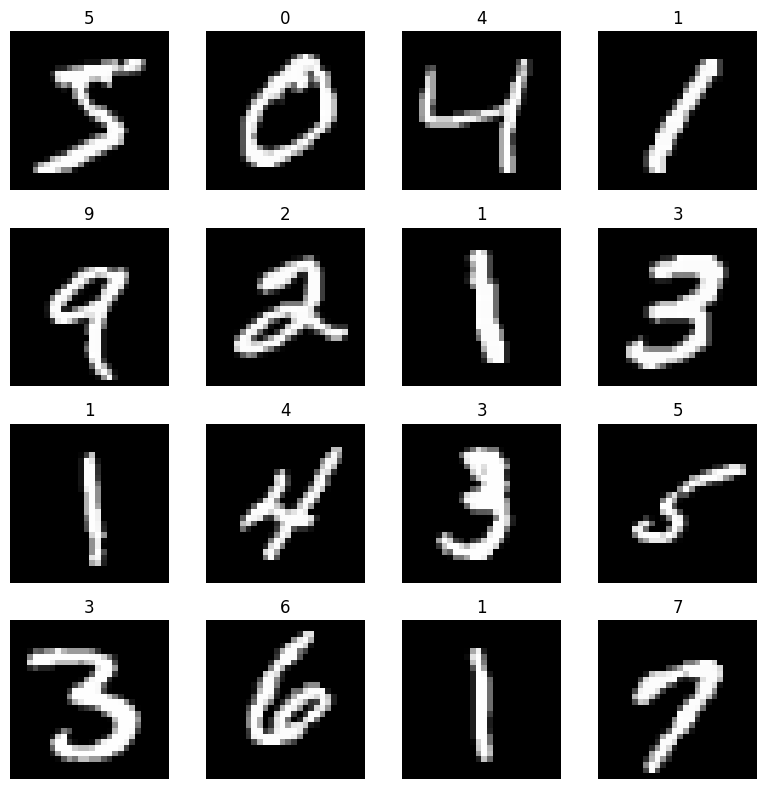

In [9]:
set_seed(CFG['seed'])
RUN_DIR = create_run_directory()
train_data, test_data = load_datasets()
show_samples(train_data, RUN_DIR)
results = []


## 6 原始图像上的 FNN 与 CNN

两个模型分别初始化、分别训练；使用相同训练集、测试集与批次种子。观察参数量接近时的表现差异，不预设最终准确率。



fnn_original: 6,442 parameters, 1 epoch(s)
  Batch 1/938 | loss=2.3615
  Batch 101/938 | loss=1.9821
  Batch 201/938 | loss=1.2937
  Batch 301/938 | loss=0.7913
  Batch 401/938 | loss=0.6972
  Batch 501/938 | loss=0.5356
  Batch 601/938 | loss=0.5496
  Batch 701/938 | loss=0.4507
  Batch 801/938 | loss=0.3674
  Batch 901/938 | loss=0.7021
Epoch 1/1 | train loss 0.8717 | test loss 0.4142 | test accuracy 87.97% (10000 samples)


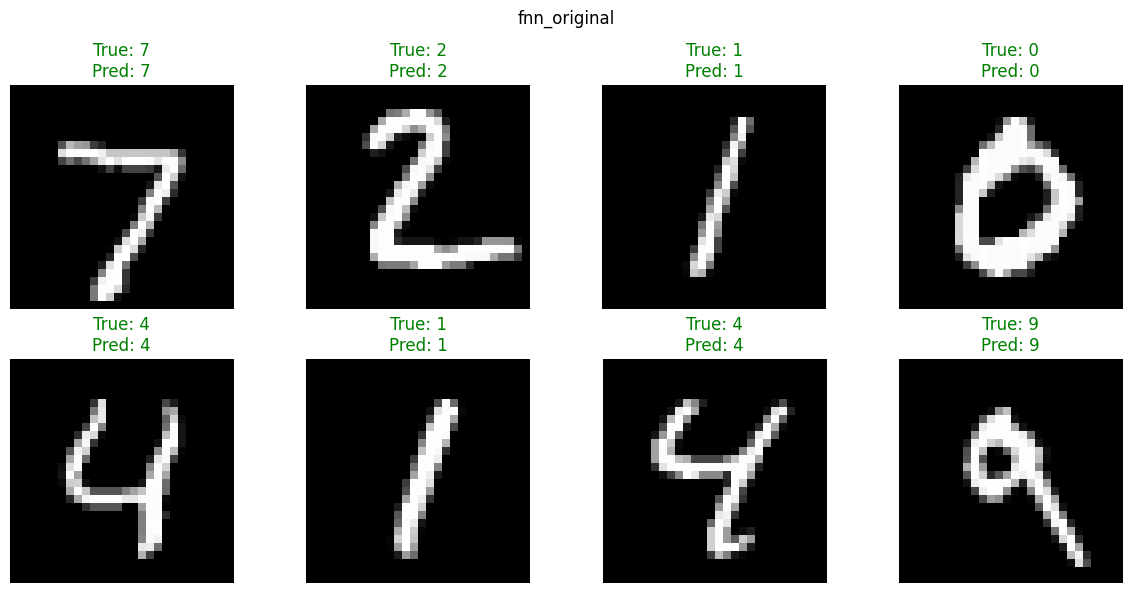


cnn_original: 6,422 parameters, 1 epoch(s)
  Batch 1/938 | loss=2.3057
  Batch 101/938 | loss=1.8049
  Batch 201/938 | loss=0.5422
  Batch 301/938 | loss=0.5177
  Batch 401/938 | loss=0.2391
  Batch 501/938 | loss=0.1788
  Batch 601/938 | loss=0.1652
  Batch 701/938 | loss=0.4211
  Batch 801/938 | loss=0.1489
  Batch 901/938 | loss=0.2292
Epoch 1/1 | train loss 0.5522 | test loss 0.1820 | test accuracy 94.32% (10000 samples)


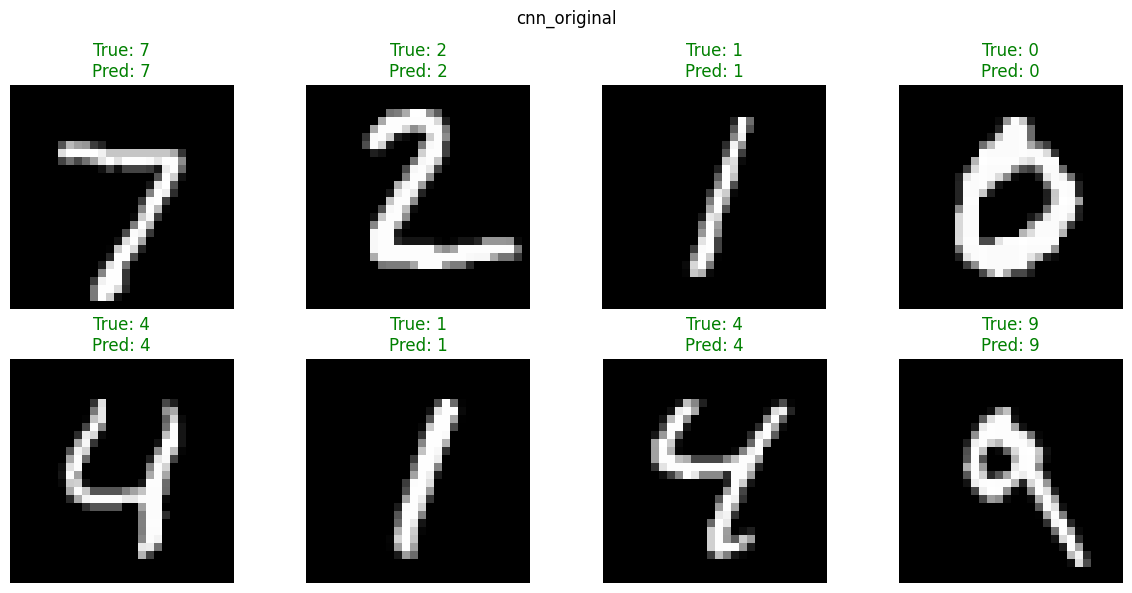

In [10]:
results = [item for item in results if item['name'] not in ('fnn_original', 'cnn_original')]
for name, model_class in [('fnn_original', FC2Layer), ('cnn_original', CNN)]:
    set_seed(CFG['seed'])
    model = model_class().to(DEVICE)
    result = fit_model(model, name, train_data, test_data, RUN_DIR, nn.NLLLoss())
    show_predictions(result, test_data, RUN_DIR)
    results.append(result)


## 7 固定像素置换对照

只生成一个 784 维置换，训练、测试、FNN、CNN 均复用它。置换改变空间邻接关系，不改变类别标签。原指导分别重新生成置换，这里统一置换以控制比较条件。


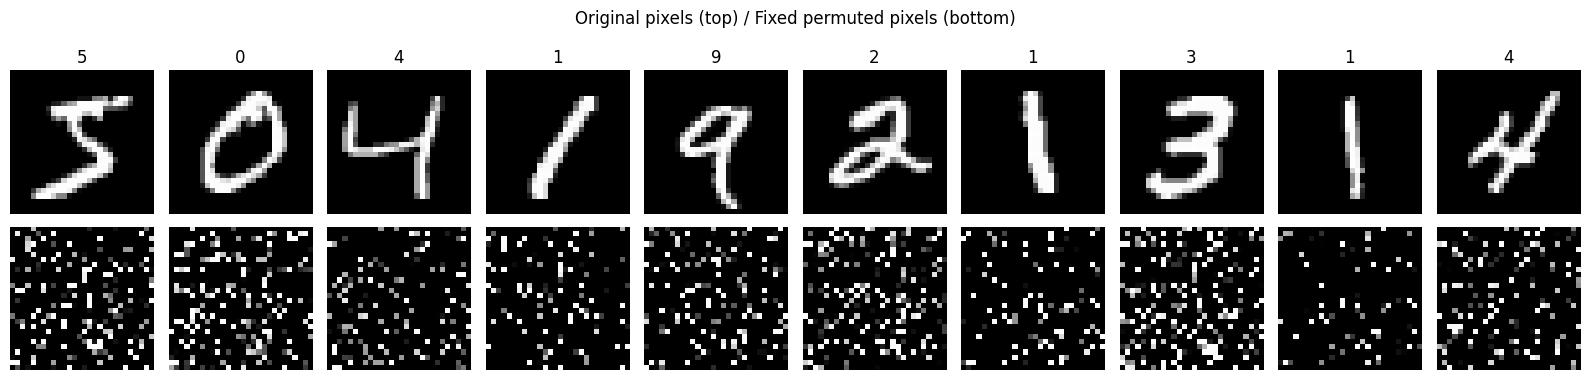


fnn_permuted: 6,442 parameters, 1 epoch(s)
  Batch 1/938 | loss=2.3838
  Batch 101/938 | loss=1.8816
  Batch 201/938 | loss=1.0840
  Batch 301/938 | loss=0.7690
  Batch 401/938 | loss=0.7345
  Batch 501/938 | loss=0.4969
  Batch 601/938 | loss=0.5716
  Batch 701/938 | loss=0.5926
  Batch 801/938 | loss=0.3933
  Batch 901/938 | loss=0.7321
Epoch 1/1 | train loss 0.8690 | test loss 0.4348 | test accuracy 87.00% (10000 samples)


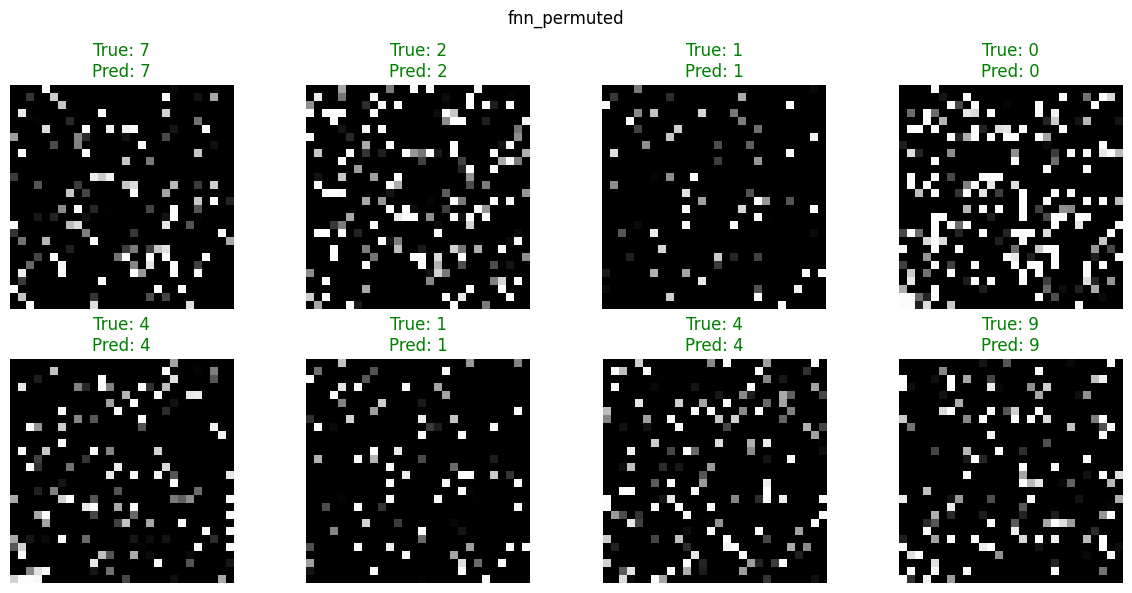


cnn_permuted: 6,422 parameters, 1 epoch(s)
  Batch 1/938 | loss=2.3018
  Batch 101/938 | loss=2.2560
  Batch 201/938 | loss=2.1833
  Batch 301/938 | loss=2.0107
  Batch 401/938 | loss=1.4341
  Batch 501/938 | loss=0.8741
  Batch 601/938 | loss=0.7994
  Batch 701/938 | loss=0.7538
  Batch 801/938 | loss=0.6520
  Batch 901/938 | loss=0.7624
Epoch 1/1 | train loss 1.3213 | test loss 0.5349 | test accuracy 83.72% (10000 samples)


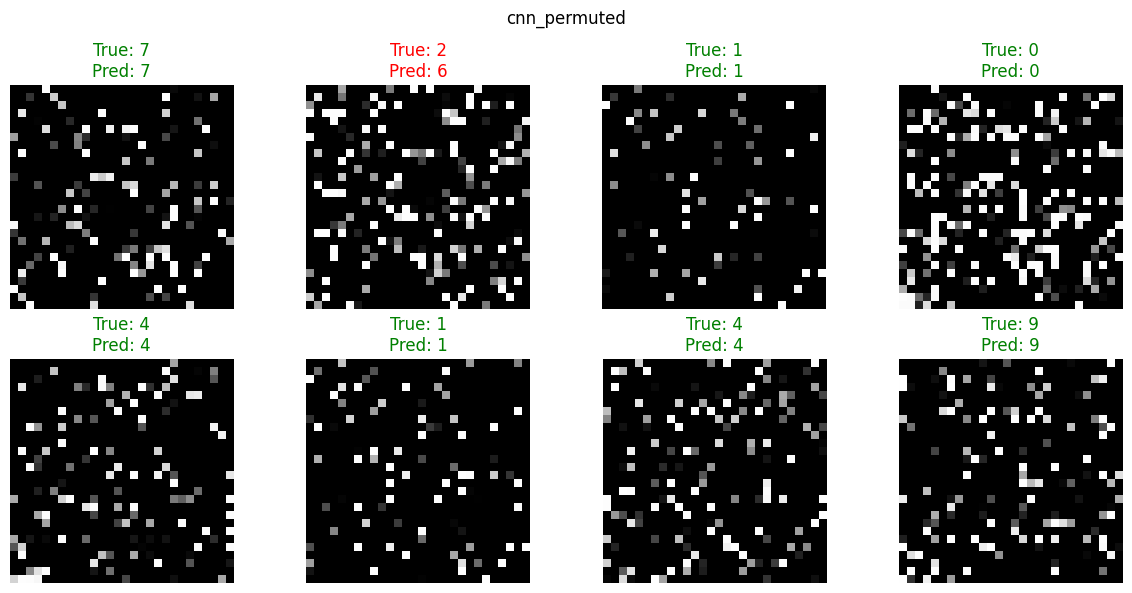

In [11]:
pixel_permutation = torch.randperm(784, generator=torch.Generator().manual_seed(CFG['seed'] + 1))
torch.save(pixel_permutation, RUN_DIR / 'pixel_permutation.pt')
show_permuted_samples(train_data, pixel_permutation, RUN_DIR)
results = [item for item in results if item['name'] not in ('fnn_permuted', 'cnn_permuted')]
for name, model_class in [('fnn_permuted', FC2Layer), ('cnn_permuted', CNN)]:
    set_seed(CFG['seed'])
    model = model_class().to(DEVICE)
    result = fit_model(model, name, train_data, test_data, RUN_DIR, nn.NLLLoss(), pixel_permutation)
    show_predictions(result, test_data, RUN_DIR)
    results.append(result)


## 8 汇总结果与导出

生成训练曲线、summary.csv、各模型 history.csv、预测图片与模型权重。ZIP 仅包含本次运行结果。导出后还应从 Colab 下载带单元输出的 ipynb，保留真实执行证据。


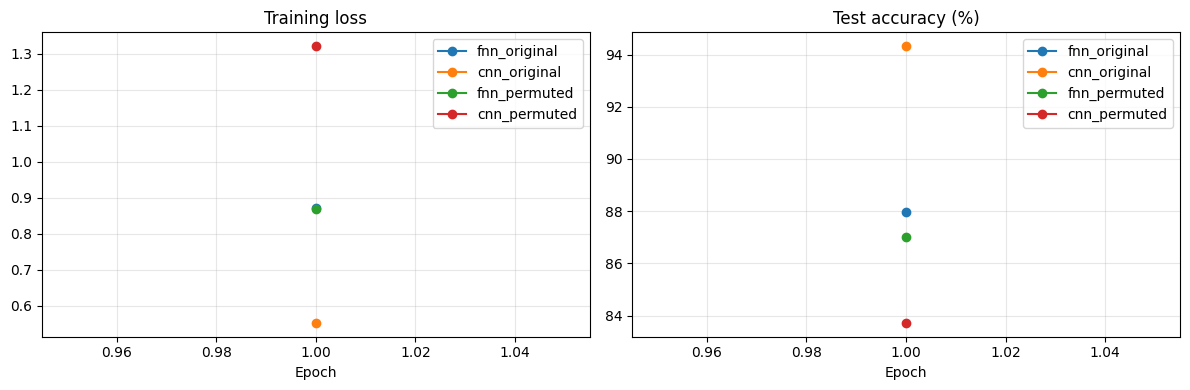


Model | Parameters | Test accuracy (%)
fnn_original | 6,442 | 87.97
cnn_original | 6,422 | 94.32
fnn_permuted | 6,442 | 87.00
cnn_permuted | 6,422 | 83.72
Results ZIP: /content/outputs/lab03_mnist_cnn/20261016_082122_282237.zip
请同时保存带运行输出的 Notebook，作为报告截图的原始依据。


In [12]:
summary = save_comparison(results, RUN_DIR)
archive_path = export_results(RUN_DIR)


## 报告记录提示

记录本次环境、参数、数据规模、训练过程、最终准确率和错误预测。选择环境检查、尺寸检查、训练日志、预测图、结果汇总作为截图。随机种子不保证不同设备和软件版本逐位一致；以本次真实结果为准。
